# **TALLER DE ANÁLISIS MULTIOBJETIVO PARA PROBLEMAS DISCRETOS**
## Selección de un automóvil mediante programación de compromiso

Curso: Introducción al Análisis de Decisiones

Universidad Nacional de Colombia, Sede Medellín

Profesora: Patricia Jaramillo Álvarez, PhD

Estudiante: Daniel Fernando Verdecia Goyeneche. Documento: 1006456802

Fecha: 13 de noviembre de 2026

Este cuaderno sigue la estructura de los cuadernos de la profesora Patricia Jaramillo (`dominancia_carros.ipynb` y `COMPROMISO_DISCRETO_CARROS_ELECTRICOS_20-07.ipynb`).

# **1. Planteamiento del problema y datos**

Se debe elegir un automóvil entre seis alternativas del año modelo 2026. El enunciado pide cambiar los modelos originales (Honda) por otros de gama similar con valores reales. Se conserva la estructura del enunciado (sedán, sedán híbrido, SUV de tres filas, SUV compacto, SUV mediano y minivan) y se trabaja con un solo fabricante, Toyota. Así el precio, el combustible y el mantenimiento provienen de la misma fuente y de la misma metodología, y las diferencias entre alternativas no se deben a criterios de medición distintos.

**Criterios y sentido de optimización**

| Criterio | Unidad | Sentido | Fuente |
|---|---|---|---|
| C1. Precio de compra | USD (MSRP base de la versión de entrada más cargo de entrega) | Minimizar | Toyota, *Sourcebook* 2026 |
| C2. Costo de combustible | USD a 5 años | Minimizar | KBB, *Cost to Own* 2026 |
| C3. Costo de mantenimiento | USD a 5 años | Minimizar | KBB, *Cost to Own* 2026 |
| C4. Seguridad | Calificación global de 1 a 5 estrellas | Maximizar | NHTSA, *5-Star Safety Ratings* |
| C5. Carga | Pies cúbicos con todas las plazas en uso | Maximizar | Toyota, *Sourcebook* 2026 |
| C6. Pasajeros | Número de plazas | Maximizar | Toyota, *Sourcebook* 2026 |

**Ajustes respecto al enunciado**

* **Combustible.** El enunciado lo expresa en "USD / MPG", pero los valores que presenta son millas por galón (a mayor valor, menor gasto). Para que el criterio sea realmente un costo, igual que el precio y el mantenimiento, se usa el gasto de combustible a cinco años en dólares que reporta KBB. Las millas por galón de la EPA se muestran aparte como verificación.
* **Mantenimiento.** El costo de los neumáticos cada 60.000 millas no se publica por modelo. Se usa el costo de mantenimiento a cinco años de KBB. KBB solo registra mantenimiento desde el cuarto año de propiedad, de modo que el valor es una cifra parcial, pero la limitación es la misma para los seis modelos.
* **Carga.** Se toma el volumen disponible detrás de la última fila de asientos en uso. Esta medida es coherente con el criterio de pasajeros, porque mide cuánto se puede cargar cuando el vehículo transporta a todos sus ocupantes.
* **Seguridad.** Se usa la calificación global de la NHTSA, que va de 1 a 5, igual que la escala del enunciado.

**Limitaciones de los datos**

* KBB calcula el combustible y el mantenimiento para su versión predeterminada de cada modelo. En cinco de los seis modelos el MSRP de KBB coincide con el de la versión de entrada de Toyota, lo que indica que ambas fuentes describen la misma versión. En el 4Runner no coinciden, por lo que sus costos de combustible y mantenimiento podrían corresponder a una versión distinta. [VERIFICAR]
* Los costos de KBB son estimaciones del proveedor y no mediciones. Se usan como valores de referencia comunes a los seis modelos.
* La calificación de la NHTSA se tomó de la versión de tracción delantera o trasera de cada modelo. En los modelos que se consultaron con más de una tracción, la calificación global es la misma.

**Fuentes** (consultadas el 13 de noviembre de 2026)

* KBB (combustible y mantenimiento a cinco años): `https://www.kbb.com/toyota/<modelo>/2026/cost-to-own/` con los modelos `corolla`, `corolla-hybrid`, `grand-highlander`, `corolla-cross`, `4runner` y `sienna`.
* NHTSA: `https://api.nhtsa.gov/SafetyRatings`, identificadores de vehículo 21642 (Corolla), 21643 (Corolla Hybrid), 21682 (Grand Highlander), 21647 (Corolla Cross), 21653 (4Runner) y 21660 (Sienna Hybrid).
* Toyota (precio, carga y pasajeros): `https://engage.toyota.com/static/sourcebooks/2026/<modelo>_sourcebook.pdf` (el Corolla Hybrid está en el documento del Corolla). El precio es el MSRP base de la versión de entrada más el cargo de entrega, procesamiento y manejo que Toyota informa por segmento: 1.195 USD en autos, 1.450 USD en SUV de entrada y 1.495 USD en SUV medianos y vans. Estos valores coinciden con el MSRP que muestra KBB en cinco de los seis modelos. En el 4Runner, KBB muestra 43.565 USD y la ficha de Toyota da 43.365 USD (41.870 + 1.495); se adopta el valor del fabricante.
* EPA: `https://www.fueleconomy.gov/ws/rest/vehicle/<id>` con los identificadores 49807, 49804, 49889, 49846, 50147 y 50111.

In [1]:
# Se importan las librerías para manipular tablas, realizar cálculos y graficar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Nombres de los criterios
criterios = [
    "Precio de compra",   # C1 (USD)
    "Combustible",        # C2 (USD a 5 años)
    "Mantenimiento",      # C3 (USD a 5 años)
    "Seguridad",          # C4 (1 a 5)
    "Carga",              # C5 (pies cúbicos)
    "Pasajeros",          # C6 (cantidad)
]

# Matriz de consecuencias
# Los criterios de costo (C1, C2 y C3) se ingresan con signo negativo para que
# todos los criterios queden en el mismo sentido: mayor es mejor.
data = [
    [-24320, -26170, -43355, -26485, -43365, -41915],      # C1 = Precio de compra
    [-4365, -3126, -6550, -4864, -6945, -4306],            # C2 = Combustible a 5 años
    [-1780, -2294, -2219, -1831, -1723, -1645],            # C3 = Mantenimiento a 5 años
    [5, 5, 5, 5, 4, 5],                                    # C4 = Seguridad (NHTSA)
    [13.1, 13.1, 20.6, 24.0, 48.4, 33.5],                  # C5 = Carga con todas las plazas en uso
    [5, 5, 8, 5, 5, 8],                                    # C6 = Pasajeros
]

# Nombres de las alternativas
alternativas = ['A1: Corolla Sedán', 'A2: Corolla Sedán Híbrido', 'A3: Grand Highlander SUV',
                'A4: Corolla Cross SUV', 'A5: 4Runner SUV', 'A6: Sienna Minivan']

# Crear el DataFrame
matriz_consecuencias = pd.DataFrame(data, index=criterios, columns=alternativas)

# Mostrar el DataFrame
print(matriz_consecuencias)

                  A1: Corolla Sedán  A2: Corolla Sedán Híbrido  \
Precio de compra           -24320.0                   -26170.0   
Combustible                 -4365.0                    -3126.0   
Mantenimiento               -1780.0                    -2294.0   
Seguridad                       5.0                        5.0   
Carga                          13.1                       13.1   
Pasajeros                       5.0                        5.0   

                  A3: Grand Highlander SUV  A4: Corolla Cross SUV  \
Precio de compra                  -43355.0               -26485.0   
Combustible                        -6550.0                -4864.0   
Mantenimiento                      -2219.0                -1831.0   
Seguridad                              5.0                    5.0   
Carga                                 20.6                   24.0   
Pasajeros                              8.0                    5.0   

                  A5: 4Runner SUV  A6: Sienna Minivan

**Datos en las unidades del enunciado.** La tabla siguiente presenta los costos con signo positivo y agrega las millas por galón combinadas de la EPA. Esta última columna no entra al modelo. Sirve para comprobar que el costo de combustible de KBB es coherente con el rendimiento real de cada vehículo.

In [2]:
# Tabla con los valores en las unidades originales (costos en positivo)
tabla_enunciado = matriz_consecuencias.abs().T

# Millas por galón combinadas (EPA, fueleconomy.gov), solo como verificación
mpg_epa = pd.Series([35, 50, 24, 32, 22, 36], index=alternativas)
tabla_enunciado['MPG combinado (EPA)'] = mpg_epa
print(tabla_enunciado)

# El mayor rendimiento (MPG) debe corresponder al menor costo de combustible
consistente = (tabla_enunciado['Combustible'].rank() == tabla_enunciado['MPG combinado (EPA)'].rank(ascending=False)).all()
print("\nEl orden del costo de combustible es coherente con el orden de MPG:", consistente)

                           Precio de compra  Combustible  Mantenimiento  \
A1: Corolla Sedán                   24320.0       4365.0         1780.0   
A2: Corolla Sedán Híbrido           26170.0       3126.0         2294.0   
A3: Grand Highlander SUV            43355.0       6550.0         2219.0   
A4: Corolla Cross SUV               26485.0       4864.0         1831.0   
A5: 4Runner SUV                     43365.0       6945.0         1723.0   
A6: Sienna Minivan                  41915.0       4306.0         1645.0   

                           Seguridad  Carga  Pasajeros  MPG combinado (EPA)  
A1: Corolla Sedán                5.0   13.1        5.0                   35  
A2: Corolla Sedán Híbrido        5.0   13.1        5.0                   50  
A3: Grand Highlander SUV         5.0   20.6        8.0                   24  
A4: Corolla Cross SUV            5.0   24.0        5.0                   32  
A5: 4Runner SUV                  4.0   48.4        5.0                   22  
A6: Si

**Costo total a cinco años.** Como referencia para interpretar los resultados, se suman los tres criterios de costo. Este total no es un criterio del modelo: cada costo se normaliza y se pondera por separado, como pide el enunciado.

In [3]:
# Costo total a 5 años = precio de compra + combustible + mantenimiento (USD)
costo_total = matriz_consecuencias.loc[['Precio de compra', 'Combustible', 'Mantenimiento']].abs().sum(axis=0)
print("Costo total a 5 años (USD)", "\n", costo_total)

Costo total a 5 años (USD) 
 A1: Corolla Sedán            30465.0
A2: Corolla Sedán Híbrido    31590.0
A3: Grand Highlander SUV     52124.0
A4: Corolla Cross SUV        33180.0
A5: 4Runner SUV              52033.0
A6: Sienna Minivan           47866.0
dtype: float64


# **2. Análisis de dominancia**

Una alternativa A domina a otra B cuando A es igual o mejor que B en todos los criterios y estrictamente mejor en al menos uno. Una alternativa dominada nunca puede ser la mejor elección, por lo que se puede descartar. Se aplica el mismo procedimiento del cuaderno de dominancia: primero se normaliza la matriz y luego se comparan todos los pares de alternativas.

**Normalización por el valor máximo y el mínimo**

Cada valor $Z_{ij}$, del criterio $i$ en la alternativa $j$, se normaliza con la expresión

$$
Z_{ij}^{\text{norm}} = \frac{Z_{ij} - \min(Z_i)}{\max(Z_i) - \min(Z_i)}
$$

Como los costos se ingresaron con signo negativo, el valor 1 siempre corresponde al mejor desempeño y el valor 0 al peor.

In [4]:
# Normalización por filas usando min-max
matriz_normalizada = matriz_consecuencias.apply(lambda fila: (fila - fila.min()) / (fila.max() - fila.min()), axis=1)
print("Matriz normalizada por filas (min-max):")
print(matriz_normalizada.round(3))

Matriz normalizada por filas (min-max):
                  A1: Corolla Sedán  A2: Corolla Sedán Híbrido  \
Precio de compra              1.000                      0.903   
Combustible                   0.676                      1.000   
Mantenimiento                 0.792                      0.000   
Seguridad                     1.000                      1.000   
Carga                         0.000                      0.000   
Pasajeros                     0.000                      0.000   

                  A3: Grand Highlander SUV  A4: Corolla Cross SUV  \
Precio de compra                     0.001                  0.886   
Combustible                          0.103                  0.545   
Mantenimiento                        0.116                  0.713   
Seguridad                            1.000                  1.000   
Carga                                0.212                  0.309   
Pasajeros                            1.000                  0.000   

             

**Código para encontrar alternativas dominadas**

In [5]:
# Transponer para trabajar más fácilmente: filas = alternativas
matriznormalizada_transpuesta = matriz_normalizada.T.copy()

# Lista que indica si cada criterio se debe maximizar (True) o minimizar (False)
# Los costos ya están con signo negativo, por lo que todos se maximizan
objetivos = [True, True, True, True, True, True]

# Convertimos todo a numpy array para procesamiento eficiente
data = matriznormalizada_transpuesta.values
n_alternativas = data.shape[0]
dominadas = set()

# Comparamos cada par de alternativas
for i in range(n_alternativas):
    for j in range(n_alternativas):
        if i == j or j in dominadas:
            continue

        mejor_o_igual = True
        estrictamente_mejor = False

        for k, maximizar in enumerate(objetivos):
            val_i = data[i, k]
            val_j = data[j, k]

            if maximizar:
                if val_i < val_j:
                    mejor_o_igual = False
                    break
                elif val_i > val_j:
                    estrictamente_mejor = True
            else:
                if val_i > val_j:
                    mejor_o_igual = False
                    break
                elif val_i < val_j:
                    estrictamente_mejor = True

        if mejor_o_igual and estrictamente_mejor:
            dominadas.add(j)

# Mostrar alternativas dominadas
alternativas = matriznormalizada_transpuesta.index.tolist()
dominadas_labels = [alternativas[i] for i in dominadas]

print("Alternativas dominadas:", dominadas_labels)

Alternativas dominadas: ['A3: Grand Highlander SUV']


**Código para encontrar quién domina a cada alternativa dominada**

In [6]:
# Convertimos a array
data = matriznormalizada_transpuesta.values
n_alternativas = data.shape[0]
alternativas = matriznormalizada_transpuesta.index.tolist()

# Diccionario para guardar quién domina a quién
dominadores = {alt: [] for alt in alternativas}

# Comparar cada par
for i in range(n_alternativas):
    for j in range(n_alternativas):
        if i == j:
            continue

        mejor_o_igual = True
        estrictamente_mejor = False

        for k, maximizar in enumerate(objetivos):
            val_i = data[i, k]
            val_j = data[j, k]

            if maximizar:
                if val_i < val_j:
                    mejor_o_igual = False
                    break
                elif val_i > val_j:
                    estrictamente_mejor = True
            else:
                if val_i > val_j:
                    mejor_o_igual = False
                    break
                elif val_i < val_j:
                    estrictamente_mejor = True

        if mejor_o_igual and estrictamente_mejor:
            dominadores[alternativas[j]].append(alternativas[i])

# Filtrar solo las alternativas que fueron dominadas
alternativas_dominadas = {alt: dom for alt, dom in dominadores.items() if len(dom) > 0}

# Mostrar resultado
for alt, quienes in alternativas_dominadas.items():
    print(f"La alternativa {alt} es dominada por: {', '.join(quienes)}")

La alternativa A3: Grand Highlander SUV es dominada por: A6: Sienna Minivan


**Efecto de eliminar las alternativas dominadas.** El enunciado permite descartarlas. Antes de hacerlo conviene comprobar si la alternativa dominada define el mejor o el peor valor de algún criterio, porque en ese caso su eliminación cambiaría la normalización min-max de las demás.

In [7]:
# Matriz sin las alternativas dominadas
matriz_sin_dominadas = matriz_consecuencias.drop(columns=dominadas_labels)

# Se compara el mejor y el peor valor de cada criterio antes y después de eliminarlas
mismo_ideal = (matriz_sin_dominadas.max(axis=1) == matriz_consecuencias.max(axis=1)).all()
mismo_peor = (matriz_sin_dominadas.min(axis=1) == matriz_consecuencias.min(axis=1)).all()

print("Alternativas eliminadas:", dominadas_labels)
print("El valor ideal de todos los criterios no cambia:", mismo_ideal)
print("El valor peor de todos los criterios no cambia:", mismo_peor)

Alternativas eliminadas: ['A3: Grand Highlander SUV']
El valor ideal de todos los criterios no cambia: True
El valor peor de todos los criterios no cambia: True


**Gráfico de Camino de Valor para todas las alternativas**

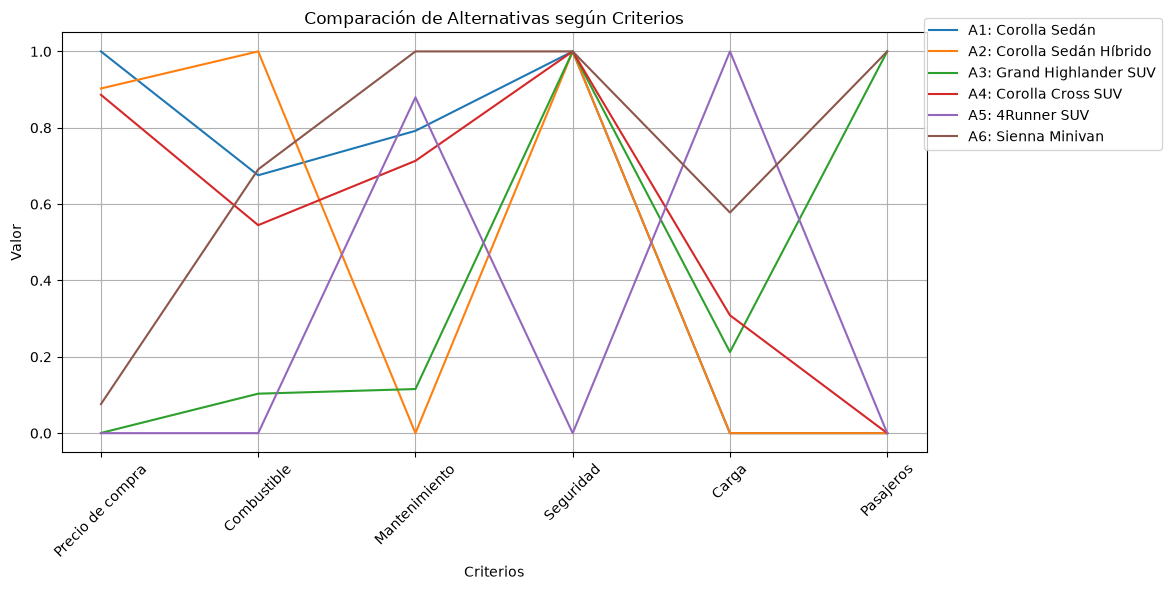

In [8]:
# Transponer el DataFrame: filas = alternativas, columnas = criterios
matriznormalizada_transpuesta = matriz_normalizada.T

# Crear el gráfico
plt.figure(figsize=(12, 6))

# Graficar una línea por cada alternativa
for alt in matriznormalizada_transpuesta.index:
    plt.plot(matriznormalizada_transpuesta.columns, matriznormalizada_transpuesta.loc[alt], label=alt)

# Personalizar el gráfico
plt.title("Comparación de Alternativas según Criterios")
plt.xlabel("Criterios")
plt.ylabel("Valor")
plt.xticks(rotation=45)
plt.legend(loc='upper right', bbox_to_anchor=(1.28, 1.05), ncol=1)
plt.grid(True)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

**Gráfico de Araña para todas las alternativas**

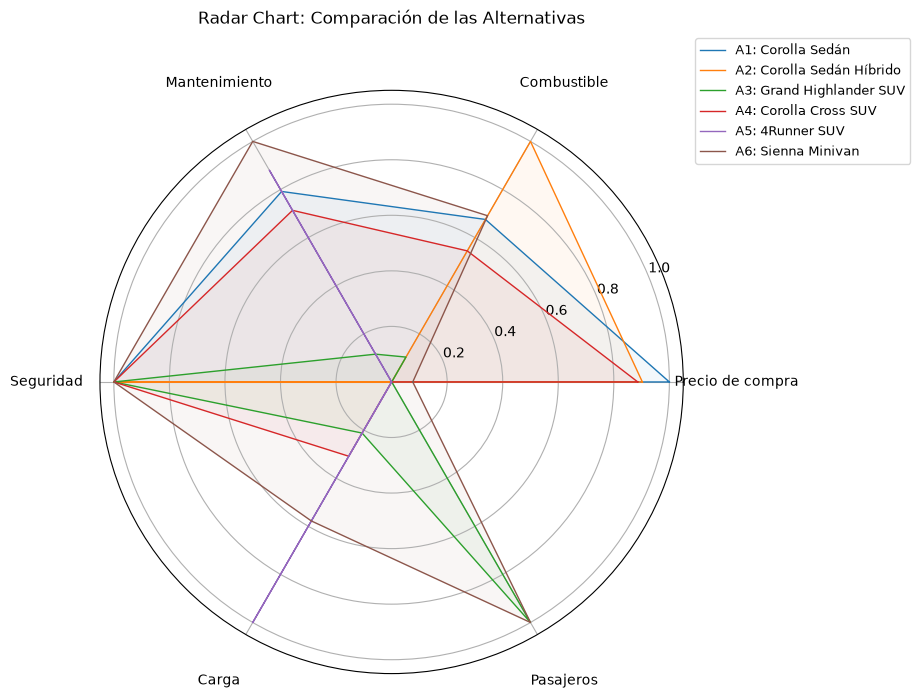

In [9]:
# Paso 1: Preparar etiquetas y ángulos
labels = matriz_normalizada.index.tolist()
num_vars = len(labels)

# Repetir el primer valor al final para cerrar el gráfico circular
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

# Paso 2: Crear figura polar
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

# Paso 3: Dibujar cada alternativa
for alt in matriz_normalizada.columns:
    values = matriz_normalizada[alt].tolist()
    values += values[:1]  # Cierre del círculo
    ax.plot(angles, values, linewidth=1, label=alt)
    ax.fill(angles, values, alpha=0.05)  # Suaviza la visibilidad

# Paso 4: Personalizar ejes
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10)
ax.tick_params(axis='x', pad=28)   # separa las etiquetas del borde del círculo
ax.set_title("Radar Chart: Comparación de las Alternativas", y=1.1)

# Paso 5: Leyenda
ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.1), ncol=1, fontsize=9)

plt.tight_layout()
plt.show()

## **Resultado del análisis de dominancia**

El algoritmo encuentra una sola alternativa dominada: **A3: Grand Highlander SUV**, dominada por **A6: Sienna Minivan**. El Sienna cuesta 1.440 USD menos en el precio de compra (41.915 frente a 43.355), gasta 2.244 USD menos en combustible y 574 USD menos en mantenimiento a cinco años. Tiene la misma calificación de seguridad (5 estrellas) y las mismas 8 plazas, y ofrece más espacio de carga (33,5 frente a 20,6 pies cúbicos). En el camino de valor y en la gráfica de araña se observa lo mismo: la línea del Grand Highlander nunca queda por encima de la del Sienna, y solo coincide con ella en seguridad y pasajeros.

Las otras cinco alternativas no son dominadas. El Corolla es el más barato, el Corolla Híbrido el de menor gasto de combustible, el Sienna el de menor mantenimiento y el 4Runner el de mayor carga. El Corolla Cross no tiene el mejor valor en ningún criterio (en seguridad comparte el máximo con otras cuatro alternativas), pero ofrece más carga que los dos sedanes con un precio cercano al del Corolla Híbrido, y ninguna alternativa lo supera en todos los criterios a la vez.

Eliminar el Grand Highlander no cambia el valor ideal ni el peor de ningún criterio, de modo que la normalización y las distancias de las otras cinco alternativas serían las mismas. Como la tabla del enunciado pide la jerarquía de las seis alternativas, se conservan en el cálculo y se interpreta el Grand Highlander como una alternativa que no puede resultar la mejor.

# **3. Programación de compromiso con pesos iguales**

El método de programación de compromiso elige la alternativa que está más cerca del punto ideal, es decir, del vector formado por el mejor valor de cada criterio. La distancia de la alternativa $j$ al ideal, con métrica $p$, es

$$
d_p(j) = \left( \sum_{i=1}^{n} \left[ w_i \, \frac{Z_i^{\text{ideal}} - Z_{ij}}{Z_i^{\text{ideal}} - Z_i^{\text{peor}}} \right]^p \right)^{1/p}
$$

donde $w_i$ es el peso del criterio $i$. Se usan las métricas $p=1$ (Manhattan), $p=2$ (Euclidiana) y $p=\infty$ (Chebyshev). Gana la alternativa con menor distancia. Con pesos iguales, $w_i = 1/6$.

In [10]:
# Se importa la librería numpy para realizar cálculos matemáticos
import numpy as np
# Se importa la librería pandas para manipular tablas
import pandas as pd
from numpy import *
import matplotlib.pyplot as plt

# Pesos iguales para los seis criterios: wi = 1/6
weights = [1/6, 1/6, 1/6, 1/6, 1/6, 1/6]

# Normalización
matriz_normalizada = matriz_consecuencias.apply(lambda fila: (fila - fila.min()) / (fila.max() - fila.min()), axis=1)

print("Matriz normalizada por filas (min-max):","\n")
print(matriz_normalizada.round(3))

ideal= matriz_consecuencias.max(axis=1)
peor= matriz_consecuencias.min(axis=1)
print ("\n","Z ideales (los costos aparecen con signo negativo)", "\n")
print (ideal)
print ("\n""Z peores","\n")
print (peor)

Matriz normalizada por filas (min-max): 

                  A1: Corolla Sedán  A2: Corolla Sedán Híbrido  \
Precio de compra              1.000                      0.903   
Combustible                   0.676                      1.000   
Mantenimiento                 0.792                      0.000   
Seguridad                     1.000                      1.000   
Carga                         0.000                      0.000   
Pasajeros                     0.000                      0.000   

                  A3: Grand Highlander SUV  A4: Corolla Cross SUV  \
Precio de compra                     0.001                  0.886   
Combustible                          0.103                  0.545   
Mantenimiento                        0.116                  0.713   
Seguridad                            1.000                  1.000   
Carga                                0.212                  0.309   
Pasajeros                            1.000                  0.000   

           

**Cálculo de la distancia normalizada al ideal por cada criterio, de forma independiente**

Nota sobre el cálculo de la distancia ponderada: cada peso debe multiplicar a la fila de su criterio. En un `DataFrame` cuyas filas son criterios, el producto `distancia_normalizada*weights` asocia los pesos con las columnas, es decir, con las alternativas. Con pesos iguales ambas formas dan lo mismo, pero con pesos distintos el resultado sería incorrecto. Por eso se usa `.mul(weights, axis=0)`, que multiplica cada fila por su peso.

In [11]:
distancia_normalizada = matriz_consecuencias.apply(lambda fila: (fila.max() - fila) / (fila.max() - fila.min()), axis=1)
#Esta matriz es equivalente a 1- matriz_normalizada
print("distancia normalizada", "\n", distancia_normalizada)

# Cada peso multiplica la fila de su criterio
distancia_ponderada= distancia_normalizada.mul(weights, axis=0)
print("\n","distancia ponderada", "\n", distancia_ponderada)

distancia normalizada 
                   A1: Corolla Sedán  A2: Corolla Sedán Híbrido  \
Precio de compra           0.000000                   0.097138   
Combustible                0.324430                   0.000000   
Mantenimiento              0.208012                   1.000000   
Seguridad                  0.000000                   0.000000   
Carga                      1.000000                   1.000000   
Pasajeros                  1.000000                   1.000000   

                  A3: Grand Highlander SUV  A4: Corolla Cross SUV  \
Precio de compra                  0.999475               0.113678   
Combustible                       0.896570               0.455093   
Mantenimiento                     0.884438               0.286595   
Seguridad                         0.000000               0.000000   
Carga                             0.787535               0.691218   
Pasajeros                         0.000000               1.000000   

                  A5: 4Runner

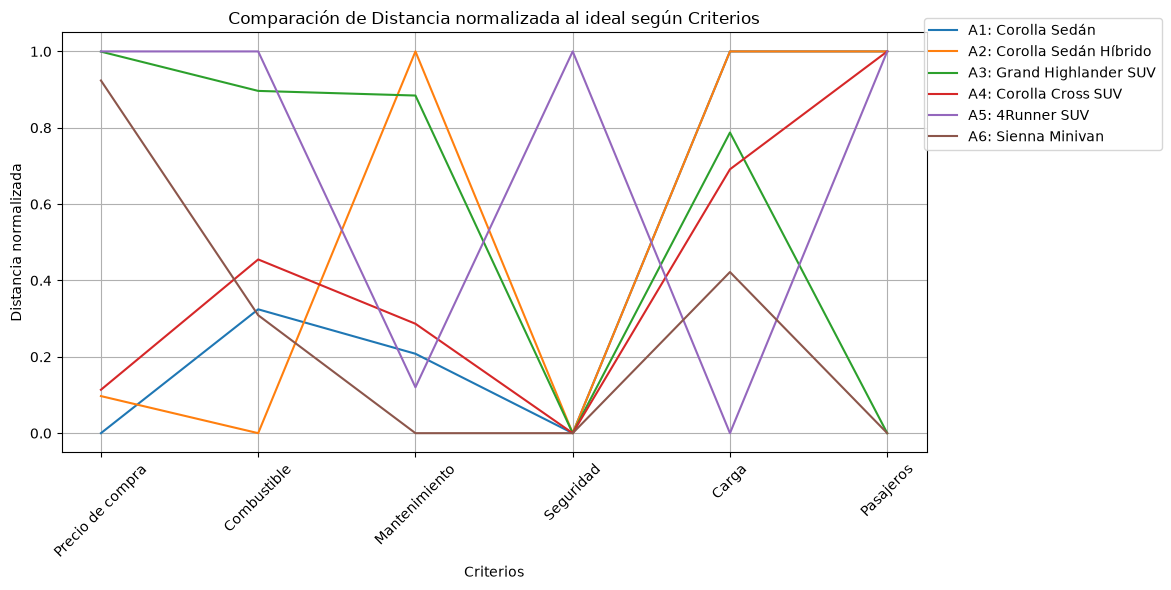

In [12]:
# Crear el gráfico
plt.figure(figsize=(12, 6))

# Transponer el DataFrame: filas = alternativas, columnas = criterios
distancia_normalizada_transpuesta = distancia_normalizada.T
# Graficar una línea por cada alternativa
for alt in distancia_normalizada_transpuesta.index:
    plt.plot(distancia_normalizada_transpuesta.columns, distancia_normalizada_transpuesta.loc[alt], label=alt)

# Personalizar el gráfico
plt.title("Comparación de Distancia normalizada al ideal según Criterios")
plt.xlabel("Criterios")
plt.ylabel("Distancia normalizada")
plt.xticks(rotation=45)
plt.legend(loc='upper right', bbox_to_anchor=(1.28, 1.05), ncol=1)
plt.grid(True)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

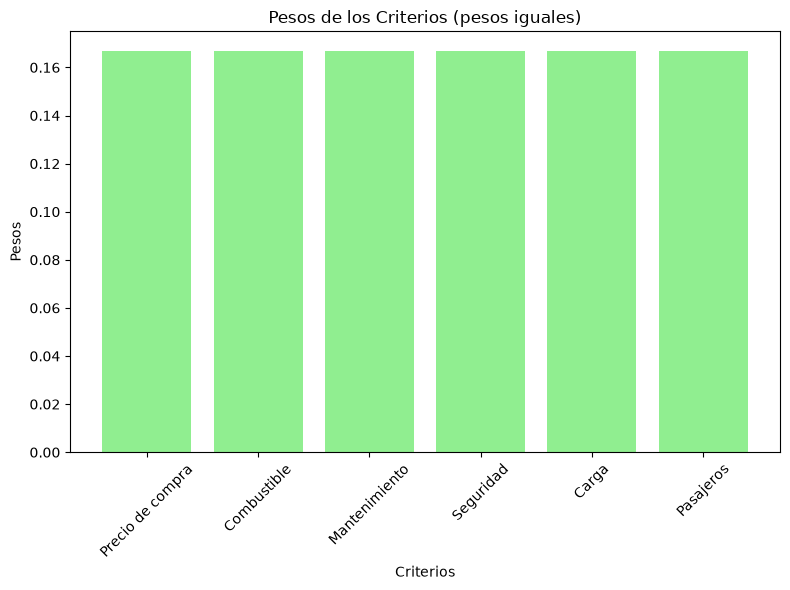

In [13]:
# Gráfico de barras para los pesos de los criterios
plt.figure(figsize=(8, 6))
plt.bar(criterios, weights, color='lightgreen')
plt.xlabel('Criterios')
plt.ylabel('Pesos')
plt.title('Pesos de los Criterios (pesos iguales)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **PROGRAMACION DE COMPROMISO METRICA UNO (MANHATTAN):**

Distancia Manhattan al ideal 
 A1: Corolla Sedán            0.422074
A2: Corolla Sedán Híbrido    0.516190
A3: Grand Highlander SUV     0.594670
A4: Corolla Cross SUV        0.424431
A5: 4Runner SUV              0.686697
A6: Sienna Minivan           0.275824
dtype: float64
la mejor alternativa es segun metrica uno:  A6: Sienna Minivan


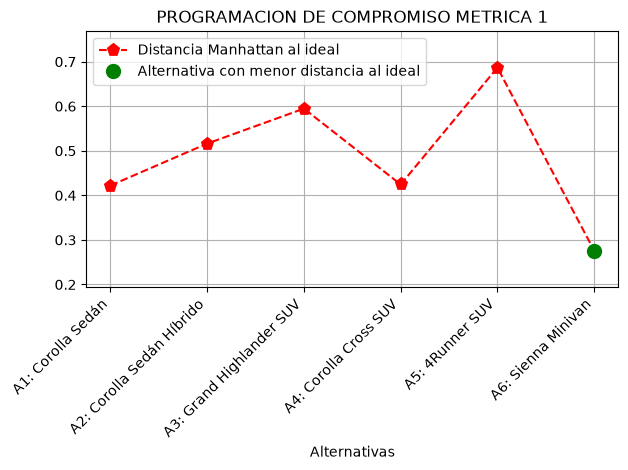

In [14]:
p=1

dis_manhatan = (sum(distancia_ponderada, 0))

print("Distancia Manhattan al ideal","\n", dis_manhatan)

# Encontrar la alternativa con menor distancia al ideal
min_manhatan_index = argmin(dis_manhatan)
min_manhatan_value = dis_manhatan.iloc[min_manhatan_index]
# Si hay empate en la menor distancia, se identifican todas las alternativas empatadas
mejores_manhatan = np.where(np.isclose(dis_manhatan, min_manhatan_value))[0]

print( "la mejor alternativa es segun metrica uno: ", ", ".join(alternativas[i] for i in mejores_manhatan))

q = [i + 1 for i in range(len(alternativas))]
plt.plot(q, dis_manhatan, 'p--', color = 'red',
markeredgewidth = 2, markersize = 8)
plt.plot([q[i] for i in mejores_manhatan], dis_manhatan.iloc[mejores_manhatan], 'o', color='green', markersize=10, label=f'Min dideal: {min_manhatan_value:.4f}')


plt.title(f'PROGRAMACION DE COMPROMISO METRICA {p}')
plt.legend(['Distancia Manhattan al ideal', 'Alternativa con menor distancia al ideal'])

plt.xticks(q, alternativas, rotation=45, ha='right')

# Dynamic Y-axis adjustment
min_val = dis_manhatan.min()
max_val = dis_manhatan.max()
range_val = max_val - min_val
margin = range_val * 0.2
new_ymin = np.maximum(0, min_val - margin)
new_ymax = max_val + margin
plt.ylim(new_ymin, new_ymax)

plt.xlabel('Alternativas')
plt.grid(True)
plt.tight_layout()
plt.show()

# **PROGRAMACION DE COMPROMISO METRICA 2 (EUCLIDIANA):**

Distancia Euclidiana al ideal 
 A1: Corolla Sedán            0.244297
A2: Corolla Sedán Híbrido    0.289129
A3: Grand Highlander SUV     0.298386
A4: Corolla Cross SUV        0.222358
A5: 4Runner SUV              0.333935
A6: Sienna Minivan           0.176946
dtype: float64

 la mejor alternativa es segun metrica dos:  A6: Sienna Minivan


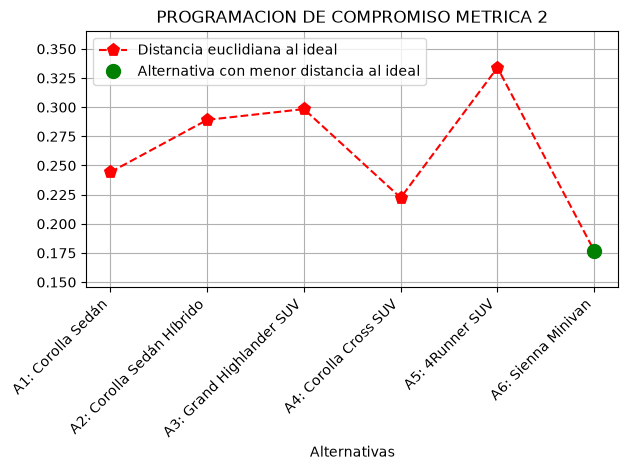

In [15]:
p=2

dis_euclidiana = (sum(distancia_ponderada**p, 0))**(1/p)

print("Distancia Euclidiana al ideal", "\n", dis_euclidiana)


# Encontrar la alternativa con menor distancia al ideal
min_euclidiana_index = argmin(dis_euclidiana)
min_euclidiana_value = dis_euclidiana.iloc[min_euclidiana_index]
# Si hay empate en la menor distancia, se identifican todas las alternativas empatadas
mejores_euclidiana = np.where(np.isclose(dis_euclidiana, min_euclidiana_value))[0]

print("\n", "la mejor alternativa es segun metrica dos: ", ", ".join(alternativas[i] for i in mejores_euclidiana))

q = [i + 1 for i in range(len(alternativas))]
plt.plot(q, dis_euclidiana, 'p--', color = 'red',
markeredgewidth = 2, markersize = 8)
plt.plot([q[i] for i in mejores_euclidiana], dis_euclidiana.iloc[mejores_euclidiana], 'o', color='green', markersize=10, label=f'Min dideal: {min_euclidiana_value:.4f}')


plt.title(f'PROGRAMACION DE COMPROMISO METRICA {p}')
plt.legend(['Distancia euclidiana al ideal', 'Alternativa con menor distancia al ideal'])

plt.xticks(q, alternativas, rotation=45, ha='right')

# Dynamic Y-axis adjustment
min_val = dis_euclidiana.min()
max_val = dis_euclidiana.max()
range_val = max_val - min_val
margin = range_val * 0.2
new_ymin = np.maximum(0, min_val - margin)
new_ymax = max_val + margin
plt.ylim(new_ymin, new_ymax)

plt.xlabel('Alternativas')
plt.grid(True)
plt.tight_layout()
plt.show()

# **PROGRAMACION DE COMPROMISO METRICA INFINITO (Chebyshev):**

Distancia Chebyshev al ideal 
 A1: Corolla Sedán            0.166667
A2: Corolla Sedán Híbrido    0.166667
A3: Grand Highlander SUV     0.166579
A4: Corolla Cross SUV        0.166667
A5: 4Runner SUV              0.166667
A6: Sienna Minivan           0.153977
dtype: float64

 la mejor alternativa es segun metrica infinito:  A6: Sienna Minivan


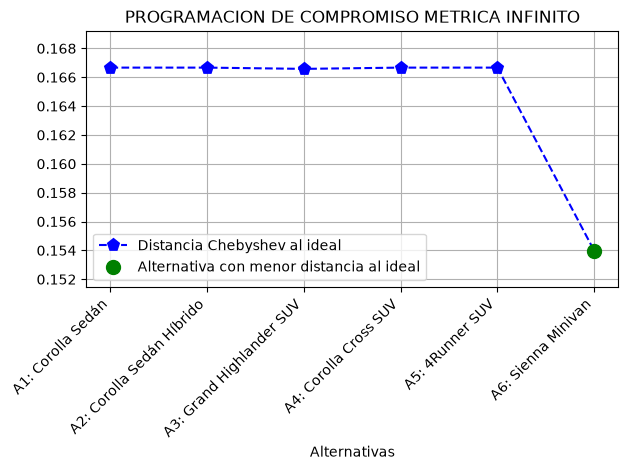

In [16]:
#Para p = infinito, distancia = max (w (Zideal- Zij)(Zideal.Zpeor))

dideal_inf=(max(distancia_ponderada, 0))

print("Distancia Chebyshev al ideal","\n", dideal_inf)

# Encontrar la alternativa con menor distancia al ideal
min_dideal_indexI = argmin(dideal_inf)
min_dideal_valueI = dideal_inf.iloc[min_dideal_indexI]
# Si hay empate en la menor distancia, se identifican todas las alternativas empatadas
mejores_inf = np.where(np.isclose(dideal_inf, min_dideal_valueI))[0]

print( "\n","la mejor alternativa es segun metrica infinito: ", ", ".join(alternativas[i] for i in mejores_inf))

q = [i + 1 for i in range(len(alternativas))]
plt.plot(q, dideal_inf, 'p--', color = 'blue',markeredgewidth = 2, markersize = 8)

plt.plot([q[i] for i in mejores_inf], dideal_inf.iloc[mejores_inf], 'o', color='green', markersize=10, label=f'Min dideal: {min_dideal_valueI:.4f}')
plt.title(f'PROGRAMACION DE COMPROMISO METRICA INFINITO')
plt.legend(['Distancia Chebyshev al ideal', 'Alternativa con menor distancia al ideal'])
plt.xticks(q, alternativas, rotation=45, ha='right')

# Dynamic Y-axis adjustment
min_val = dideal_inf.min()
max_val = dideal_inf.max()
range_val = max_val - min_val
margin = range_val * 0.2
new_ymin = np.maximum(0, min_val - margin)
new_ymax = max_val + margin
plt.ylim(new_ymin, new_ymax)

plt.xlabel('Alternativas')
plt.grid(True)
plt.tight_layout()
plt.show()

**Tabla de jerarquías con pesos iguales**

In [17]:
# Distancias al ideal con cada métrica
distancias = pd.DataFrame({
    'Distancia p=1': dis_manhatan,
    'Distancia p=2': dis_euclidiana,
    'Distancia p=infinito': dideal_inf,
})
print("Distancias al ideal", "\n", distancias.round(4))

# Jerarquía: 1 es la alternativa más cercana al ideal. Las distancias iguales comparten posición.
jerarquia = distancias.round(10).rank(method='min').astype(int)
jerarquia.columns = ['Jerarquía compromiso p=1', 'Jerarquía compromiso p=2', 'Jerarquía compromiso p=infinito']
print("\n", "Tabla de jerarquías", "\n", jerarquia)

# Se guardan los resultados para compararlos más adelante con los pesos del decisor
distancias_iguales = distancias.copy()
jerarquia_iguales = jerarquia.copy()

Distancias al ideal 
                            Distancia p=1  Distancia p=2  Distancia p=infinito
A1: Corolla Sedán                 0.4221         0.2443                0.1667
A2: Corolla Sedán Híbrido         0.5162         0.2891                0.1667
A3: Grand Highlander SUV          0.5947         0.2984                0.1666
A4: Corolla Cross SUV             0.4244         0.2224                0.1667
A5: 4Runner SUV                   0.6867         0.3339                0.1667
A6: Sienna Minivan                0.2758         0.1769                0.1540

 Tabla de jerarquías 
                            Jerarquía compromiso p=1  Jerarquía compromiso p=2  \
A1: Corolla Sedán                                 2                         3   
A2: Corolla Sedán Híbrido                         4                         4   
A3: Grand Highlander SUV                          5                         5   
A4: Corolla Cross SUV                             3                         2   
A5:

## **Resultados con pesos iguales ($w_i = 1/6 \approx 0,167$)**

| Alternativa | Jerarquía compromiso p=1 | Jerarquía compromiso p=2 | Jerarquía compromiso p=infinito |
|---|:---:|:---:|:---:|
| A1: Corolla Sedán | 2 | 3 | 3 |
| A2: Corolla Sedán Híbrido | 4 | 4 | 3 |
| A3: Grand Highlander SUV | 5 | 5 | 2 |
| A4: Corolla Cross SUV | 3 | 2 | 3 |
| A5: 4Runner SUV | 6 | 6 | 3 |
| A6: Sienna Minivan | 1 | 1 | 1 |

Distancias al ideal que sustentan la jerarquía:

| Alternativa | Distancia p=1 | Distancia p=2 | Distancia p=infinito |
|---|:---:|:---:|:---:|
| A1: Corolla Sedán | 0,4221 | 0,2443 | 0,1667 |
| A2: Corolla Sedán Híbrido | 0,5162 | 0,2891 | 0,1667 |
| A3: Grand Highlander SUV | 0,5947 | 0,2984 | 0,1666 |
| A4: Corolla Cross SUV | 0,4244 | 0,2224 | 0,1667 |
| A5: 4Runner SUV | 0,6867 | 0,3339 | 0,1667 |
| A6: Sienna Minivan | 0,2758 | 0,1769 | 0,1540 |

**Comparación de las soluciones.** Las tres métricas coinciden en el primer lugar: **A6: Sienna Minivan**, con distancias de 0,2758 (p=1), 0,1769 (p=2) y 0,1540 (p=infinito). Ninguno de sus criterios está en el peor valor. Su punto débil es el precio, con una distancia normalizada de 0,92, pero lo compensa con el menor costo de mantenimiento, la mejor seguridad, ocho plazas y una carga intermedia. El Corolla, el Corolla Híbrido, el Corolla Cross y el 4Runner tienen al menos un criterio en su peor valor, y eso los deja más lejos del ideal en las tres métricas.

El Grand Highlander (quinto en p=1 y p=2) y el 4Runner (sexto en ambas) ocupan los dos últimos lugares. Esto es coherente con el análisis de dominancia: el primero está dominado por el Sienna y el segundo tiene la menor seguridad, el mayor costo de combustible y el precio más alto.

Entre el Corolla y el Corolla Cross hay un cambio de orden. Con p=1 el Corolla queda segundo y el Corolla Cross tercero, pero la diferencia es de solo 0,0024, prácticamente un empate. Con p=2 el Corolla Cross pasa adelante, porque la métrica euclidiana penaliza más los desempeños extremos y el Corolla tiene dos criterios en su peor valor (carga y pasajeros) frente a uno del Corolla Cross (pasajeros).

La métrica p=infinito aporta poca información en este caso. Solo mide el criterio con peor desempeño, y como el Corolla, el Corolla Híbrido, el Corolla Cross y el 4Runner tienen al menos un criterio en su peor valor, los cuatro obtienen la misma distancia máxima de $1/6$ (0,1667) y quedan empatados en el tercer puesto. El Grand Highlander aparece segundo solo por una diferencia de 0,00009, que proviene de que su precio está 10 USD por debajo del peor valor (el del 4Runner). Es un efecto de la normalización y no una ventaja real, porque el Sienna lo domina.

**Conclusión.** Con pesos iguales el Sienna es la mejor alternativa de forma consistente. La conclusión es sólida porque las tres métricas la respaldan y porque el Sienna domina a una de las alternativas, mientras que ninguna lo domina a él.

# **4. Programación de compromiso con los pesos del decisor**

Los pesos se definen de forma jerárquica, igual que la estructura del enunciado: primero se reparte la importancia entre los tres criterios principales (Costo, Seguridad y Capacidad) y luego se subdivide dentro de cada uno.

El perfil adoptado es el de un comprador que usará el vehículo para transportar a su familia y que prioriza el costo y la seguridad:

* **Costo (50 %).** Es la restricción principal de la compra. Dentro del costo, el precio de compra pesa 50 %, el combustible 30 % y el mantenimiento 20 %. El precio es el desembolso inicial y el más alto, mientras que el combustible se repite en cada uso del vehículo.
* **Seguridad (30 %).** Se asigna un peso alto porque el vehículo transportará personas.
* **Capacidad (20 %).** Es una necesidad real pero menos determinante. Dentro de ella, el número de pasajeros pesa 60 % y el volumen de carga 40 %.

Estos pesos reflejan la posición del decisor y pueden modificarse en la celda siguiente. Si se cambian, basta con volver a ejecutar las celdas de esta sección y de la comparación final.

In [18]:
# Pesos de los tres criterios principales (deben sumar 1)
w_costo = 0.50
w_seguridad = 0.30
w_capacidad = 0.20

# Reparto dentro de cada criterio principal (cada grupo debe sumar 1)
reparto_costo = [0.50, 0.30, 0.20]      # Precio de compra, Combustible, Mantenimiento
reparto_capacidad = [0.40, 0.60]        # Carga, Pasajeros

# Peso final de cada criterio, en el mismo orden de la matriz de consecuencias
weights = [w_costo*reparto_costo[0], w_costo*reparto_costo[1], w_costo*reparto_costo[2],
           w_seguridad,
           w_capacidad*reparto_capacidad[0], w_capacidad*reparto_capacidad[1]]

# Verificación: los pesos deben sumar 1
print("Suma de los pesos:", np.isclose(sum(weights), 1))

tabla_pesos = pd.DataFrame({'Criterio': criterios, 'Wi': weights})
print("\n", tabla_pesos.to_string(index=False))

distancia_ponderada= distancia_normalizada.mul(weights, axis=0)
print("\n","distancia ponderada", "\n", distancia_ponderada)

Suma de los pesos: True

         Criterio   Wi
Precio de compra 0.25
     Combustible 0.15
   Mantenimiento 0.10
       Seguridad 0.30
           Carga 0.08
       Pasajeros 0.12

 distancia ponderada 
                   A1: Corolla Sedán  A2: Corolla Sedán Híbrido  \
Precio de compra           0.000000                   0.024285   
Combustible                0.048665                   0.000000   
Mantenimiento              0.020801                   0.100000   
Seguridad                  0.000000                   0.000000   
Carga                      0.080000                   0.080000   
Pasajeros                  0.120000                   0.120000   

                  A3: Grand Highlander SUV  A4: Corolla Cross SUV  \
Precio de compra                  0.249869               0.028420   
Combustible                       0.134485               0.068264   
Mantenimiento                     0.088444               0.028659   
Seguridad                         0.000000               

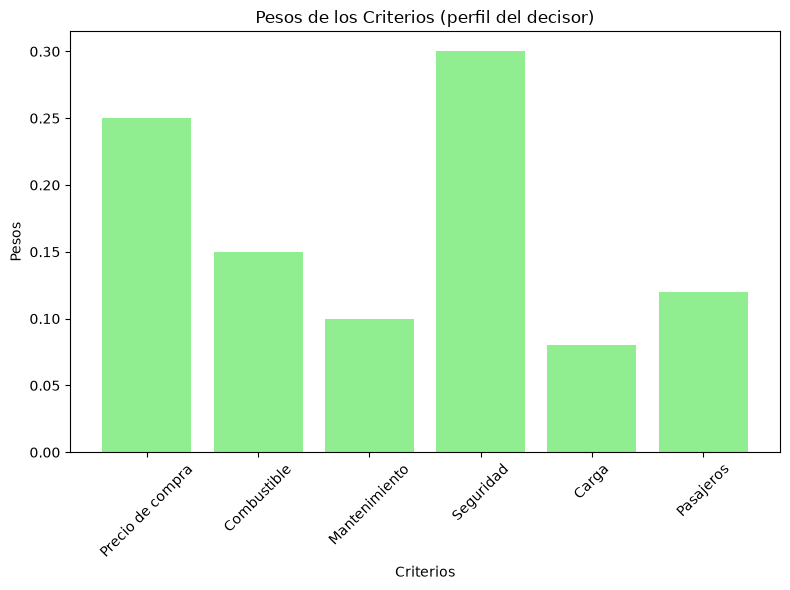

In [19]:
# Gráfico de barras para los pesos de los criterios
plt.figure(figsize=(8, 6))
plt.bar(criterios, weights, color='lightgreen')
plt.xlabel('Criterios')
plt.ylabel('Pesos')
plt.title('Pesos de los Criterios (perfil del decisor)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **PROGRAMACION DE COMPROMISO METRICA UNO (MANHATTAN):**

Distancia Manhattan al ideal 
 A1: Corolla Sedán            0.269466
A2: Corolla Sedán Híbrido    0.324285
A3: Grand Highlander SUV     0.535801
A4: Corolla Cross SUV        0.300640
A5: 4Runner SUV              0.832018
A6: Sienna Minivan           0.311081
dtype: float64
la mejor alternativa es segun metrica uno:  A1: Corolla Sedán


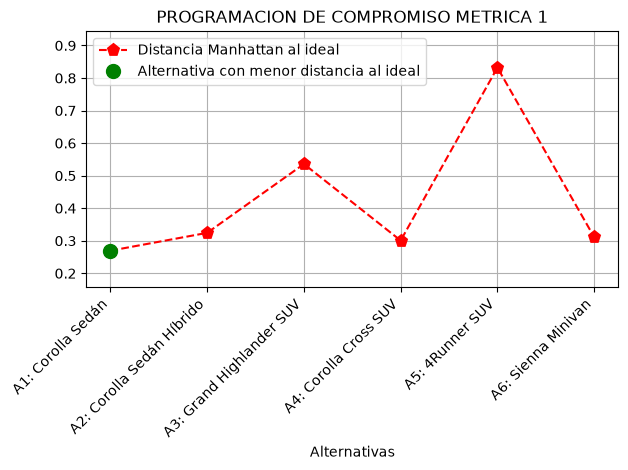

In [20]:
p=1

dis_manhatan = (sum(distancia_ponderada, 0))

print("Distancia Manhattan al ideal","\n", dis_manhatan)

# Encontrar la alternativa con menor distancia al ideal
min_manhatan_index = argmin(dis_manhatan)
min_manhatan_value = dis_manhatan.iloc[min_manhatan_index]
# Si hay empate en la menor distancia, se identifican todas las alternativas empatadas
mejores_manhatan = np.where(np.isclose(dis_manhatan, min_manhatan_value))[0]

print( "la mejor alternativa es segun metrica uno: ", ", ".join(alternativas[i] for i in mejores_manhatan))

q = [i + 1 for i in range(len(alternativas))]
plt.plot(q, dis_manhatan, 'p--', color = 'red',
markeredgewidth = 2, markersize = 8)
plt.plot([q[i] for i in mejores_manhatan], dis_manhatan.iloc[mejores_manhatan], 'o', color='green', markersize=10, label=f'Min dideal: {min_manhatan_value:.4f}')


plt.title(f'PROGRAMACION DE COMPROMISO METRICA {p}')
plt.legend(['Distancia Manhattan al ideal', 'Alternativa con menor distancia al ideal'])

plt.xticks(q, alternativas, rotation=45, ha='right')

# Dynamic Y-axis adjustment
min_val = dis_manhatan.min()
max_val = dis_manhatan.max()
range_val = max_val - min_val
margin = range_val * 0.2
new_ymin = np.maximum(0, min_val - margin)
new_ymax = max_val + margin
plt.ylim(new_ymin, new_ymax)

plt.xlabel('Alternativas')
plt.grid(True)
plt.tight_layout()
plt.show()

# **PROGRAMACION DE COMPROMISO METRICA 2 (EUCLIDIANA):**

Distancia Euclidiana al ideal 
 A1: Corolla Sedán            0.153626
A2: Corolla Sedán Híbrido    0.177172
A3: Grand Highlander SUV     0.303830
A4: Corolla Cross SUV        0.154100
A5: 4Runner SUV              0.435367
A6: Sienna Minivan           0.237978
dtype: float64

 la mejor alternativa es segun metrica dos:  A1: Corolla Sedán


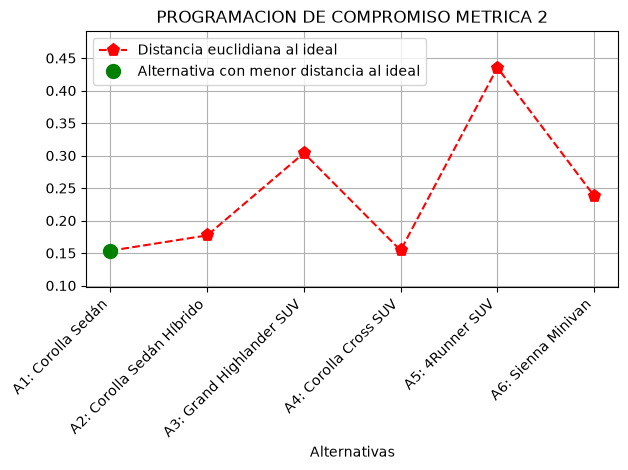

In [21]:
p=2

dis_euclidiana = (sum(distancia_ponderada**p, 0))**(1/p)

print("Distancia Euclidiana al ideal", "\n", dis_euclidiana)


# Encontrar la alternativa con menor distancia al ideal
min_euclidiana_index = argmin(dis_euclidiana)
min_euclidiana_value = dis_euclidiana.iloc[min_euclidiana_index]
# Si hay empate en la menor distancia, se identifican todas las alternativas empatadas
mejores_euclidiana = np.where(np.isclose(dis_euclidiana, min_euclidiana_value))[0]

print("\n", "la mejor alternativa es segun metrica dos: ", ", ".join(alternativas[i] for i in mejores_euclidiana))

q = [i + 1 for i in range(len(alternativas))]
plt.plot(q, dis_euclidiana, 'p--', color = 'red',
markeredgewidth = 2, markersize = 8)
plt.plot([q[i] for i in mejores_euclidiana], dis_euclidiana.iloc[mejores_euclidiana], 'o', color='green', markersize=10, label=f'Min dideal: {min_euclidiana_value:.4f}')


plt.title(f'PROGRAMACION DE COMPROMISO METRICA {p}')
plt.legend(['Distancia euclidiana al ideal', 'Alternativa con menor distancia al ideal'])

plt.xticks(q, alternativas, rotation=45, ha='right')

# Dynamic Y-axis adjustment
min_val = dis_euclidiana.min()
max_val = dis_euclidiana.max()
range_val = max_val - min_val
margin = range_val * 0.2
new_ymin = np.maximum(0, min_val - margin)
new_ymax = max_val + margin
plt.ylim(new_ymin, new_ymax)

plt.xlabel('Alternativas')
plt.grid(True)
plt.tight_layout()
plt.show()

# **PROGRAMACION DE COMPROMISO METRICA INFINITO (Chebyshev):**

Distancia Chebyshev al ideal 
 A1: Corolla Sedán            0.120000
A2: Corolla Sedán Híbrido    0.120000
A3: Grand Highlander SUV     0.249869
A4: Corolla Cross SUV        0.120000
A5: 4Runner SUV              0.300000
A6: Sienna Minivan           0.230966
dtype: float64

 la mejor alternativa es segun metrica infinito:  A1: Corolla Sedán, A2: Corolla Sedán Híbrido, A4: Corolla Cross SUV


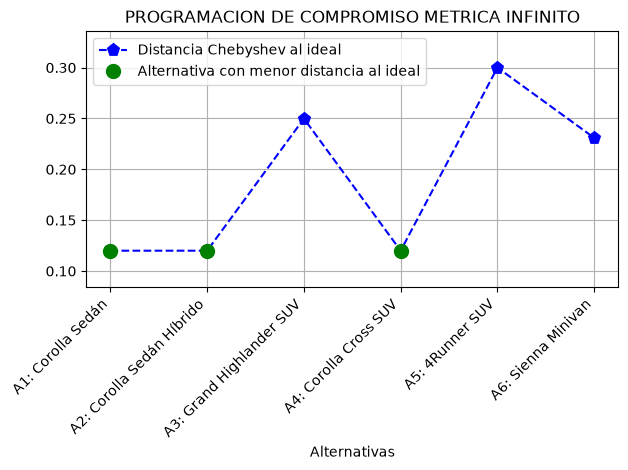

In [22]:
#Para p = infinito, distancia = max (w (Zideal- Zij)(Zideal.Zpeor))

dideal_inf=(max(distancia_ponderada, 0))

print("Distancia Chebyshev al ideal","\n", dideal_inf)

# Encontrar la alternativa con menor distancia al ideal
min_dideal_indexI = argmin(dideal_inf)
min_dideal_valueI = dideal_inf.iloc[min_dideal_indexI]
# Si hay empate en la menor distancia, se identifican todas las alternativas empatadas
mejores_inf = np.where(np.isclose(dideal_inf, min_dideal_valueI))[0]

print( "\n","la mejor alternativa es segun metrica infinito: ", ", ".join(alternativas[i] for i in mejores_inf))

q = [i + 1 for i in range(len(alternativas))]
plt.plot(q, dideal_inf, 'p--', color = 'blue',markeredgewidth = 2, markersize = 8)

plt.plot([q[i] for i in mejores_inf], dideal_inf.iloc[mejores_inf], 'o', color='green', markersize=10, label=f'Min dideal: {min_dideal_valueI:.4f}')
plt.title(f'PROGRAMACION DE COMPROMISO METRICA INFINITO')
plt.legend(['Distancia Chebyshev al ideal', 'Alternativa con menor distancia al ideal'])
plt.xticks(q, alternativas, rotation=45, ha='right')

# Dynamic Y-axis adjustment
min_val = dideal_inf.min()
max_val = dideal_inf.max()
range_val = max_val - min_val
margin = range_val * 0.2
new_ymin = np.maximum(0, min_val - margin)
new_ymax = max_val + margin
plt.ylim(new_ymin, new_ymax)

plt.xlabel('Alternativas')
plt.grid(True)
plt.tight_layout()
plt.show()

**Tabla de jerarquías con los pesos del decisor**

In [23]:
# Distancias al ideal con cada métrica
distancias = pd.DataFrame({
    'Distancia p=1': dis_manhatan,
    'Distancia p=2': dis_euclidiana,
    'Distancia p=infinito': dideal_inf,
})
print("Distancias al ideal", "\n", distancias.round(4))

# Jerarquía: 1 es la alternativa más cercana al ideal. Las distancias iguales comparten posición.
jerarquia = distancias.round(10).rank(method='min').astype(int)
jerarquia.columns = ['Jerarquía compromiso p=1', 'Jerarquía compromiso p=2', 'Jerarquía compromiso p=infinito']
print("\n", "Tabla de jerarquías", "\n", jerarquia)

# Se guardan los resultados del perfil del decisor
distancias_perfil = distancias.copy()
jerarquia_perfil = jerarquia.copy()

Distancias al ideal 
                            Distancia p=1  Distancia p=2  Distancia p=infinito
A1: Corolla Sedán                 0.2695         0.1536                0.1200
A2: Corolla Sedán Híbrido         0.3243         0.1772                0.1200
A3: Grand Highlander SUV          0.5358         0.3038                0.2499
A4: Corolla Cross SUV             0.3006         0.1541                0.1200
A5: 4Runner SUV                   0.8320         0.4354                0.3000
A6: Sienna Minivan                0.3111         0.2380                0.2310

 Tabla de jerarquías 
                            Jerarquía compromiso p=1  Jerarquía compromiso p=2  \
A1: Corolla Sedán                                 1                         1   
A2: Corolla Sedán Híbrido                         4                         3   
A3: Grand Highlander SUV                          5                         5   
A4: Corolla Cross SUV                             2                         2   
A5:

# **5. Comparación entre pesos iguales y pesos del decisor**

La tabla siguiente pone lado a lado la jerarquía de cada alternativa con las tres métricas. La columna de cambio indica cuántos puestos se mueve cada alternativa al pasar de pesos iguales a los pesos del decisor (un valor negativo significa que sube en la jerarquía).

In [24]:
# Jerarquías de ambos escenarios
comparacion = pd.concat([jerarquia_iguales.add_suffix(' (iguales)'), jerarquia_perfil.add_suffix(' (perfil)')], axis=1)

# Cambio de posición al pasar de pesos iguales a los pesos del decisor
cambio = pd.DataFrame({
    'Cambio p=1': jerarquia_perfil.iloc[:, 0] - jerarquia_iguales.iloc[:, 0],
    'Cambio p=2': jerarquia_perfil.iloc[:, 1] - jerarquia_iguales.iloc[:, 1],
    'Cambio p=infinito': jerarquia_perfil.iloc[:, 2] - jerarquia_iguales.iloc[:, 2],
})
print("Jerarquías en ambos escenarios", "\n", comparacion)
print("\n", "Cambio de posición (perfil - iguales)", "\n", cambio)

# Alternativa(s) en el primer lugar de cada métrica y escenario
print()
for nombre, jer in [('pesos iguales', jerarquia_iguales), ('pesos del decisor', jerarquia_perfil)]:
    for col in jer.columns:
        primeras = jer.index[jer[col] == 1].tolist()
        print(f"{nombre} | {col}: {', '.join(primeras)}")

# Margen entre la menor y la segunda menor distancia de cada métrica
# (un margen cercano a cero indica que la primera posición es prácticamente un empate)
print()
for nombre, dist in [('pesos iguales', distancias_iguales), ('pesos del decisor', distancias_perfil)]:
    for col in dist.columns:
        ordenadas = dist[col].sort_values()
        print(f"{nombre} | {col}: margen entre la 1.ª y la 2.ª = {ordenadas.iloc[1] - ordenadas.iloc[0]:.4f}")

Jerarquías en ambos escenarios 
                            Jerarquía compromiso p=1 (iguales)  \
A1: Corolla Sedán                                           2   
A2: Corolla Sedán Híbrido                                   4   
A3: Grand Highlander SUV                                    5   
A4: Corolla Cross SUV                                       3   
A5: 4Runner SUV                                             6   
A6: Sienna Minivan                                          1   

                           Jerarquía compromiso p=2 (iguales)  \
A1: Corolla Sedán                                           3   
A2: Corolla Sedán Híbrido                                   4   
A3: Grand Highlander SUV                                    5   
A4: Corolla Cross SUV                                       2   
A5: 4Runner SUV                                             6   
A6: Sienna Minivan                                          1   

                           Jerarquía compromiso p=infin

## **Resultados con los pesos del decisor**

Pesos usados:

| Criterio | Wi |
|---|:---:|
| Precio de compra | 0,25 |
| Combustible | 0,15 |
| Mantenimiento | 0,10 |
| Seguridad | 0,30 |
| Carga | 0,08 |
| Pasajeros | 0,12 |

| Alternativa | Jerarquía compromiso p=1 | Jerarquía compromiso p=2 | Jerarquía compromiso p=infinito |
|---|:---:|:---:|:---:|
| A1: Corolla Sedán | 1 | 1 | 1 |
| A2: Corolla Sedán Híbrido | 4 | 3 | 1 |
| A3: Grand Highlander SUV | 5 | 5 | 5 |
| A4: Corolla Cross SUV | 2 | 2 | 1 |
| A5: 4Runner SUV | 6 | 6 | 6 |
| A6: Sienna Minivan | 3 | 4 | 4 |

Distancias al ideal que sustentan la jerarquía:

| Alternativa | Distancia p=1 | Distancia p=2 | Distancia p=infinito |
|---|:---:|:---:|:---:|
| A1: Corolla Sedán | 0,2695 | 0,1536 | 0,1200 |
| A2: Corolla Sedán Híbrido | 0,3243 | 0,1772 | 0,1200 |
| A3: Grand Highlander SUV | 0,5358 | 0,3038 | 0,2499 |
| A4: Corolla Cross SUV | 0,3006 | 0,1541 | 0,1200 |
| A5: 4Runner SUV | 0,8320 | 0,4354 | 0,3000 |
| A6: Sienna Minivan | 0,3111 | 0,2380 | 0,2310 |

**Comparación con los pesos iguales.** Sí hay una diferencia, y afecta a la alternativa ganadora. Con pesos iguales el Sienna es el primero en las tres métricas. Con los pesos del decisor baja al puesto 3 en p=1 y al puesto 4 en p=2 y p=infinito, y el primer lugar lo ocupa el **A1: Corolla Sedán** (en p=infinito lo comparte con el Corolla Híbrido y el Corolla Cross). La causa es que el perfil asigna 50 % al costo, y el Sienna es uno de los tres vehículos más caros (41.915 USD, con una distancia normalizada de 0,92 al mejor precio). Sus ventajas en pasajeros y mantenimiento pesan menos en este perfil, con 12 % y 10 % respectivamente.

Otros aspectos no cambian. Con p=1 y p=2, los mismos cuatro vehículos (Corolla, Corolla Cross, Corolla Híbrido y Sienna) ocupan los cuatro primeros puestos en ambos escenarios, y el Grand Highlander y el 4Runner siguen en el quinto y el sexto lugar. El peso de 30 % en seguridad no altera el orden entre los cinco modelos con cinco estrellas, porque todos tienen distancia cero en ese criterio. Su efecto es castigar al 4Runner (cuatro estrellas), que ya era el último con pesos iguales.

En p=infinito, el Corolla, el Corolla Híbrido y el Corolla Cross empatan en 0,12. Los tres tienen cinco plazas, que es el peor valor en pasajeros, y el peso de ese criterio (0,12) define su distancia máxima. Con p=2 la diferencia entre el Corolla y el Corolla Cross es de solo 0,0005, por lo que también se pueden considerar empatados en esa métrica.

**Conclusión y elección.** Elegiría el **Toyota Corolla (A1)**, por las siguientes razones:

1. Ocupa el primer lugar con p=1 y con p=2, y comparte el primero con p=infinito, es decir, es la mejor alternativa o una de las mejores en las tres métricas.
2. Es el vehículo más barato en precio (24.320 USD) y el de menor costo total a cinco años (30.465 USD, sumando precio, combustible y mantenimiento), que son los criterios con mayor peso en mi perfil.
3. Tiene la calificación máxima de seguridad de la NHTSA (cinco estrellas).

El Corolla cede en carga (13,1 pies cúbicos, la más baja junto con el Corolla Híbrido) y en número de plazas (cinco, frente a las ocho del Sienna y del Grand Highlander). Ambos criterios pertenecen a Capacidad, que en mi perfil pesa 20 %, por eso la decisión resulta aceptable. El Corolla Híbrido, aunque gasta 1.239 USD menos en combustible en cinco años, cuesta 1.850 USD más de compra y 514 USD más en mantenimiento, de modo que su costo total a cinco años es 1.125 USD mayor, y el ahorro de combustible no compensa ese sobrecosto.

La elección depende de las necesidades que representa el perfil. Si se requiriera más espacio de carga sin salir de las alternativas de menor costo, la opción sería el Corolla Cross (24,0 pies cúbicos), a cambio de 2.715 USD más a cinco años. Si hubiera que transportar ocho personas, la mejor opción sería el Sienna, que con pesos iguales es la primera y que supera al Grand Highlander, la otra alternativa de ocho plazas, en los dos escenarios.